# Dados, corpus e evidências

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/andrelfo85/Atividade_Goodreads/blob/master/unidade_01/03_dados_corpus_e_evidencias.ipynb)

O Notebook 02 definiu como conceitos poderiam ser observados. Este
notebook pergunta em quais materiais e sob quais critérios essas
observações formarão um corpus capaz de sustentar evidências.

## Retomada

1. Qual é sua unidade de análise?
2. Que indicador você propôs e de qual fonte ele seria extraído?

As respostas ligam representação e fonte. Para delimitar o alcance da
análise, começaremos distinguindo população, amostra e corpus.

## 1. População, amostra e corpus

- **População:** conjunto de unidades sobre o qual se deseja formular uma
  afirmação.
- **Amostra:** subconjunto observado segundo algum procedimento de seleção.
- **Corpus:** conjunto de materiais reunidos e delimitados para análise,
  comum em estudos documentais, linguísticos e culturais.

![Três painéis diferenciam população como universo, amostra como subconjunto selecionado e corpus como conjunto de materiais delimitado para análise.](https://github.com/andrelfo85/Atividade_Goodreads/blob/master/unidade_01/imagens/03_populacao_amostra_corpus.svg?raw=1)

*Um corpus pode coincidir parcialmente com uma população ou ser formado
por seleção, preservação e acesso, mas não deve ser chamado
automaticamente de amostra representativa.*

Os termos não são intercambiáveis. Nem todo corpus é uma amostra
probabilística. Uma coleção digital disponível pode resultar de preservação,
catalogação, direitos autorais, digitalização e mecanismos de busca; sua
existência não garante representatividade.

In [16]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_01'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente preparado em: /content/disciplina_computacao_aplicada_humanidades_digitais/unidade_01


### Como ler a importação

`pd.read_csv(...)` lê o arquivo tabular e cria um `DataFrame`. O caminho é
relativo à pasta da unidade, para que o exemplo funcione em outros
computadores. Antes de executar, preveja o número de linhas a partir da
descrição da coleção.

In [17]:
import json
from pathlib import Path
import pandas as pd

PASTA_DADOS = Path("dados")
if not PASTA_DADOS.exists():
    PASTA_DADOS = Path("unidade_01/dados")

documentos = pd.read_csv(PASTA_DADOS / "documentos_exemplo.csv")
documentos

,id,ano,periodico,genero,local,tema,palavras
0,D001,1890,Jornal Aurora,editorial,Capital,progresso,860
1,D002,1891,Jornal Aurora,carta,Interior,trabalho,420
2,D003,1892,Gazeta Popular,notícia,Capital,educação,610
3,D004,1893,Gazeta Popular,editorial,Capital,progresso,940
4,D005,1894,Correio do Vale,carta,Interior,educação,380
5,D006,1895,Correio do Vale,notícia,Interior,trabalho,550
6,D007,1900,Jornal Aurora,notícia,Capital,educação,720
7,D008,1901,Jornal Aurora,editorial,Capital,trabalho,1010
8,D009,1902,Gazeta Popular,carta,Interior,progresso,460
9,D010,1903,Gazeta Popular,notícia,Capital,trabalho,670


## 2. Critérios de inclusão e exclusão

Nomear o conjunto não explica como ele foi formado. Os critérios de
inclusão e exclusão tornam a passagem do universo disponível ao corpus
explícita, reproduzível e criticável.

Um corpus deve ser definido por regras justificáveis e reproduzíveis:

- período;
- local;
- autoria ou instituição;
- gênero documental;
- idioma;
- disponibilidade e qualidade;
- pertinência temática;
- condições éticas e legais.

Disponibilidade pode ser uma condição prática, mas não deve ser ocultada
como se fosse uma propriedade teórica do fenômeno.

`between(1890, 1895)` testa o intervalo para cada linha; a condição entre
colchetes seleciona os registros verdadeiros. O segundo filtro compara a
coluna `genero` com “editorial”. Os dois corpus respondem a critérios
diferentes, portanto sustentam afirmações diferentes.

In [18]:
# Corpus A: todos os documentos entre 1890 e 1895.
corpus_a = documentos[documentos["ano"].between(1890, 1895)].copy()

# Corpus B: apenas editoriais, em todo o período disponível.
corpus_b = documentos[documentos["genero"] == "editorial"].copy()

print("Corpus A:", len(corpus_a), "documentos")
print("Corpus B:", len(corpus_b), "documentos")

Corpus A: 6 documentos
Corpus B: 4 documentos


In [ ]:
comparacao = pd.DataFrame({
    "colecao_completa": documentos["tema"].value_counts(),
    "corpus_1890_1895": corpus_a["tema"].value_counts(),
    "apenas_editoriais": corpus_b["tema"].value_counts(),
}).fillna(0).astype(int)
comparacao

,colecao_completa,corpus_1890_1895,apenas_editoriais
tema,,,
progresso,4,2,2
trabalho,4,2,1
educação,4,2,1


A distribuição muda quando muda o critério. Isso não demonstra que um
corpus seja “tendencioso” e o outro “neutro”; demonstra que toda conclusão
precisa declarar a qual conjunto se refere e por que ele foi constituído.

## Estudo de caso brasileiro — população escravizada de Mariana

O exemplo fictício torna os critérios visíveis, mas não expõe toda a
complexidade de fontes históricas reais. O estudo de Rodrigues permite
examinar como seleção, categorias e ética se articulam em um projeto.

Rodrigues (2020) examina a construção de uma base sobre a população
escravizada de Mariana no século XVIII. O caso mostra que transpor fontes
produzidas sob a escravidão para uma base não é simples digitalização:
categorias, nomes, marcas corporais, proveniência e ausências envolvem
decisões éticas e metodológicas em um país racialmente desigual.

Após a leitura orientada, identifique:

1. qual problema histórico orienta a base;
2. quem produziu as fontes originais e com quais finalidades;
3. quem modela, financia e mantém os dados;
4. que categorias podem reproduzir violência documental;
5. como preservar rastreabilidade sem naturalizar classificações;
6. que usos públicos ou acadêmicos exigem cautela.

Compare o estudo real à coleção fictícia: quais problemas foram
simplificados no exemplo didático?

## 3. Três formas de organização dos dados

Delimitado o corpus, é preciso reconhecer como seus materiais chegam ao
pesquisador. A forma de organização condiciona o que pode ser consultado
diretamente e o que exige transformação.

- **Estruturados:** seguem esquema explícito, como uma tabela com colunas.
- **Semiestruturados:** possuem marcas e hierarquias flexíveis, como JSON ou
  XML.
- **Não estruturados:** não apresentam previamente uma tabela de campos,
  como texto corrido, áudio e muitas imagens.

“Não estruturado” não significa sem forma ou sem contexto. Um texto possui
estrutura linguística e documental; a expressão indica que essa estrutura
não está previamente organizada como campos regulares para computação.

| Arquivo do exemplo | Classificação neste notebook | Por quê? |
|---|---|---|
| CSV (`documentos_exemplo.csv`) | Estruturado | Os registros seguem o mesmo esquema de linhas e colunas, com um campo definido para cada característica. |
| JSON (`metadados_exemplo.json`) | Semiestruturado | As informações possuem chaves e organização explícita, mas podem formar listas e objetos hierárquicos, sem depender de uma tabela regular. |
| TXT (`texto_exemplo.txt`) | Não estruturado | O conteúdo chega como texto contínuo, sem campos computacionais previamente marcados para tema, local ou gênero. |

A classificação descreve **como a informação está organizada neste
exemplo**, e não uma propriedade absoluta da extensão do arquivo. Um JSON
submetido a um esquema rígido, por exemplo, pode ser tratado como dado
estruturado. O código seguinte permite observar essas diferenças na
prática.

In [19]:
# CSV: estrutura tabular
print(documentos.dtypes)

# JSON: chaves, listas e objetos aninhados
with (PASTA_DADOS / "metadados_exemplo.json").open(encoding="utf-8") as arquivo:
    metadados = json.load(arquivo)
print("\nTítulo da coleção:", metadados["titulo"])
print("Cobertura:", metadados["cobertura_temporal"])

# TXT: conteúdo textual a ser interpretado ou transformado
texto_documento = (PASTA_DADOS / "texto_exemplo.txt").read_text(encoding="utf-8")
print("\nTexto:", texto_documento)

id           object
ano           int64
periodico    object
genero       object
local        object
tema         object
palavras      int64
dtype: object

Título da coleção: Coleção didática de periódicos
Cobertura: {'inicio': 1890, 'fim': 1905}

Texto: Nesta edição fictícia, o periódico debate a abertura de uma escola noturna. O texto associa instrução, trabalho e progresso, mas não registra as vozes das pessoas que frequentariam a instituição. Este fragmento foi criado exclusivamente para atividades didáticas.



## 4. Documentos e metadados

Estrutura de arquivo não equivale a significado documental. A próxima
distinção separa o conteúdo da fonte dos metadados que a identificam,
contextualizam e ligam à sua materialidade.

O conteúdo do documento e seus metadados respondem a perguntas distintas.
Buscar “educação” no texto não equivale a usar uma categoria temática
atribuída por catalogação. O primeiro procedimento depende da palavra
registrada; o segundo depende de uma interpretação e de uma regra.

Metadados também têm história: podem conter erros, lacunas, vocabulários
institucionais e revisões posteriores. Devem ser avaliados como fontes.

### Materialidade documental — um periódico real

Observe a primeira página abaixo antes de reduzi-la a campos. Título, data,
preço, público presumido, organização da página, textos e ilustrações são
dimensões diferentes do objeto. Uma tabela pode registrar algumas delas,
mas não substitui o documento.

![Primeira página de A Estação, de 15 de julho de 1890, com título, data, preços de assinatura, colunas de texto e ilustrações de moda.](https://github.com/andrelfo85/Atividade_Goodreads/blob/master/unidade_01/imagens/03_periodico_1890.jpg?raw=1)

*A Estação: Jornal Illustrado para a Familia*, n. 13, 15 jul. 1890.
Acervo da Fundação Biblioteca Nacional — Brasil, via Wikimedia Commons,
domínio público. Esta página **não integra a coleção fictícia** dos
exercícios; é apresentada apenas para discutir documento, materialidade e
metadados. Créditos completos em `imagens/README.md`.

In [20]:
print("Campos documentados:")
for campo in metadados["campos"]:
    print(f"- {campo['nome']}: {campo['descricao']}")

print("\nLimitações declaradas:")
for limite in metadados["limitacoes"]:
    print(f"- {limite}")

Campos documentados:
- id: identificador do documento
- ano: ano atribuído ao documento
- periodico: título fictício do periódico
- genero: gênero documental atribuído
- local: localidade em categoria ampla
- tema: tema dominante atribuído manualmente
- palavras: extensão simulada em palavras

Limitações declaradas:
- coleção pequena e não representativa
- categorias simplificadas para fins didáticos
- ausência do texto integral de cada documento
- intervalos temporais descontínuos


## 5. Evidência computacional e interpretação humanística

Com corpus, formatos, documentos e metadados definidos, podemos acompanhar
como uma operação produz um resultado e como esse resultado se torna — ou
não — evidência para uma interpretação.

### Objetivo da seção

Esta seção distingue o que está registrado nos dados, o que o computador
calcula e o que o pesquisador pode interpretar. Esses níveis se relacionam,
mas não são equivalentes:

| Nível | Neste exemplo | Questão de controle |
|---|---|---|
| Dados registrados | valores `Capital` e `Interior` na coluna `local` | o que significa `local` e quem atribuiu essa categoria? |
| Operação computacional | contar quantas vezes cada valor aparece | qual regra o código aplica? |
| Resultado computacional | seis registros em cada categoria | o resultado está tecnicamente correto para esta tabela? |
| Evidência para a pesquisa | resultado mobilizado para responder a uma pergunta delimitada | que afirmação o corpus e a operação conseguem sustentar? |
| Interpretação humanística | explicação situada do significado e dos limites do resultado | que contexto, fontes e bibliografia são necessários? |

Um resultado não se transforma automaticamente em evidência para qualquer
afirmação. Ele pode funcionar como evidência quando a pergunta, a origem
dos dados, as categorias, a operação e o alcance da conclusão estão
explicitados.

### A cadeia de produção da evidência

| Etapa | Aplicação ao exemplo didático | Pergunta crítica |
|---|---|---|
| Fonte | documentos representados pela coleção fictícia | quem produziu os documentos e em que contexto? |
| Seleção | doze registros incluídos na coleção | por que estes registros foram incluídos e outros não? |
| Digitalização | conversão ou transcrição para formato computacional, simplificada no exemplo sintético | o que foi perdido, corrigido ou normalizado? |
| Descrição | campos como `id`, `ano`, `local` e `tema` | quem definiu e preencheu os campos? |
| Transformação | organização dos registros em CSV e carregamento no pandas | valores foram agrupados ou alterados? |
| Operação | aplicação de `value_counts()` à coluna `local` | o que exatamente está sendo contado? |
| Resultado | seis registros como `Capital` e seis como `Interior` | há ausências, grafias divergentes ou casos ambíguos? |
| Interpretação | formulação de uma afirmação sobre a coleção | a conclusão permanece dentro do alcance do corpus? |

![Cadeia em oito etapas: fonte, seleção, digitalização, descrição, transformação, operação, resultado e interpretação, com retorno para revisão.](https://github.com/andrelfo85/Atividade_Goodreads/blob/master/unidade_01/imagens/03_cadeia_evidencia.svg?raw=1)

*A operação ocupa apenas uma etapa. O valor do resultado como evidência
depende das decisões anteriores e do limite dado à interpretação.*

Cada etapa condiciona as seguintes. Uma contagem pode estar correta em
relação à tabela e ainda ser inadequada para uma afirmação histórica ampla.

### U01-A10 — Experimento — contar registros por categoria local

No código seguinte, `documentos["local"]` seleciona apenas a coluna
`local`. O método `value_counts()` agrupa valores iguais e conta quantas
linhas pertencem a cada categoria. Como cada linha representa um documento,
o resultado contará documentos **dentro desta coleção**.

Antes de executar, observe a tabela importada e formule uma previsão. O
código conhece os rótulos registrados, mas não conhece o significado
histórico de `Capital` e `Interior`, nem avalia como o corpus foi formado.

In [21]:
contagem_local = documentos["local"].value_counts()
contagem_local

,count
local,
Capital,6
Interior,6


### Como ler a saída

| Categoria registrada | Número de registros |
|---|---:|
| Capital | 6 |
| Interior | 6 |

A soma é doze, correspondente ao número de documentos da coleção. O
resultado descreve a distribuição do campo `local`; ele não explica por
que a distribuição é igual nem demonstra que a coleção representa uma
população histórica.

| Afirmação | Avaliação | Justificativa |
|---|---|---|
| “Na coleção didática, seis registros estão classificados como Capital e seis como Interior.” | Sustentada | reproduz a operação e limita o sujeito da frase ao conjunto analisado |
| “A coleção está numericamente equilibrada entre as duas categorias locais.” | Sustentada, com escopo explícito | descreve a distribuição sem generalizar para além da coleção |
| “A produção jornalística da Capital e do Interior era igual.” | Não sustentada | exigiria conhecer a população, a preservação e o procedimento de seleção |
| “O local explica as diferenças entre os documentos.” | Não sustentada | uma contagem descritiva não testa explicação nem causalidade |

A leitura também depende de pressupostos que precisam ser verificados:

- cada linha representa efetivamente um documento;
- `local` possui uma definição documentada e foi aplicado de modo
  consistente;
- valores ausentes, ambíguos ou grafados de outra forma foram identificados;
- os critérios de seleção são compatíveis com a pergunta.

Se um desses pressupostos falhar, o Python ainda poderá produzir `6` e `6`,
mas o valor do resultado como evidência será reduzido. Uma interpretação
responsável explicita o sujeito da frase — “na coleção analisada”, e não
“na sociedade” — e retorna aos documentos quando encontra um padrão.

Por isso o desenho da pesquisa é iterativo:

**pergunta → amostragem → leitura → modelagem → resultado → releitura
→ reformulação**

Neste exemplo, o equilíbrio numérico pode levar à releitura dos documentos,
à verificação da definição de `local` e ao cruzamento com `genero`, `tema`
ou `ano`. D'Ignazio e Klein (2020) ajudam a compreender por que números
dependem de contexto, teoria, trabalho de produção dos dados e relações de
poder: a operação calcula; o pesquisador constrói e limita a interpretação.

### Experimento utilizando os dados do meu projeto (Goodreads)

Operação aplicada ao campo `genero_autor` do arquivo CSV do Goodreads.

In [22]:
import subprocess
from pathlib import Path
import shutil

# URL do meu repositório específico contendo o projeto_goodreads
URL_PROJETO_USER = 'https://github.com/andrelfo85/Atividade_Goodreads.git'
PASTA_CLONADA = Path('/content/Atividade_Goodreads')
PASTA_DESTINO = Path('/content/projeto_goodreads')

if not PASTA_DESTINO.exists():
    print("Clonando repositório do projeto...")
    # Clona o repositório temporariamente
    subprocess.run(["git", "clone", "--depth", "1", URL_PROJETO_USER, str(PASTA_CLONADA)], check=True)

    # Move a pasta 'projeto_goodreads' para /content/projeto_goodreads
    origem_projeto = PASTA_CLONADA / "projeto_goodreads"
    if origem_projeto.exists():
        shutil.move(str(origem_projeto), str(PASTA_DESTINO))
        print("Pasta 'projeto_goodreads' configurada com sucesso em /content!")
    else:
        print("Erro: A pasta 'projeto_goodreads' não foi encontrada dentro do repositório clonado.")

    # Remove o restante dos arquivos clonados para manter o ambiente limpo
    if PASTA_CLONADA.exists():
        shutil.rmtree(PASTA_CLONADA)
else:
    print("A pasta 'projeto_goodreads' já está pronta para uso em /content.")

A pasta 'projeto_goodreads' já está pronta para uso em /content.


In [23]:
import sys
from pathlib import Path
import pandas as pd

# Procura a pasta do projeto de forma direta
PROJETO = next((Path(p).resolve() for p in ["projeto_goodreads", "/content/projeto_goodreads"] if (Path(p) / "preparar_base.py").exists()), None)

if PROJETO is None:
    raise FileNotFoundError("Pasta 'projeto_goodreads' não localizada. Verifique o download do repositório.")

if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

from preparar_base import ler_bruto

livros = ler_bruto()
contagem_genero = livros["genero_autor"].value_counts()
pd.DataFrame({
    "livros": contagem_genero,
    "proporcao": livros["genero_autor"].value_counts(normalize=True).round(3),
})

,livros,proporcao
genero_autor,,
masculino,5816,0.556
feminino,4638,0.444


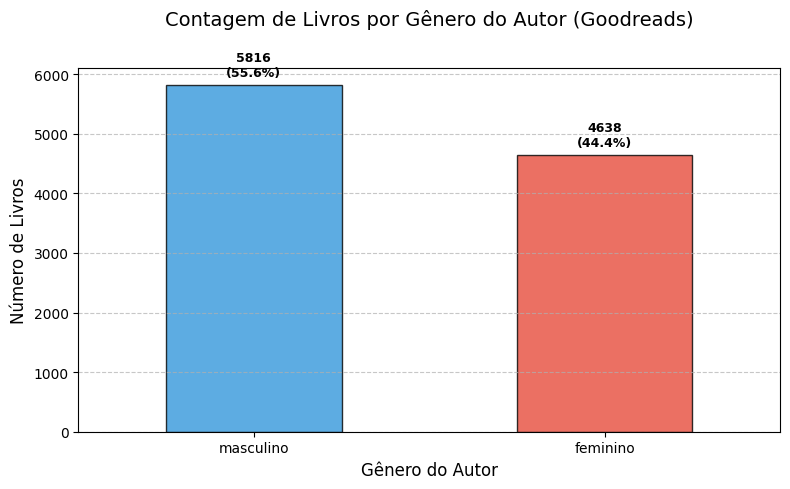

In [24]:
import matplotlib.pyplot as plt

# Criação de gráfico de barras para contagem de livros por gênero dos autores
plt.figure(figsize=(8, 5))
cores = ['#3498db', '#e74c3c']

# Plotagem
contagem_genero.plot(kind='bar', color=cores, edgecolor='black', alpha=0.8)

# Customização do gráfico
plt.title('Contagem de Livros por Gênero do Autor (Goodreads)\n', fontsize=14, pad=15)
plt.xlabel('Gênero do Autor', fontsize=12)
plt.ylabel('Número de Livros', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Exibindo os valores acima das barras
for i, valor in enumerate(contagem_genero):
    plt.text(i, valor + 100, f"{valor}\n({(valor/contagem_genero.sum()*100):.1f}%)",
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

| Afirmação | Avaliação | Justificativa |
|---|---|---|
| “No recorte recebido, 4.638 livros (44,4%) têm `genero_autor` igual a feminino e 5.816 (55,6%) igual a masculino.” | Sustentada | reproduz a operação e limita o sujeito ao arquivo |
| “Há mais livros de autoria registrada como masculina do que feminina neste recorte.” | Sustentada, com escopo explícito | descreve o arquivo, sem generalizar |
| “Os homens escrevem mais livros do que as mulheres.” | Não sustentada | exigiria conhecer a população de livros publicados e o critério de seleção do recorte |
| “O Goodreads favorece autores homens.” | Não sustentada | uma contagem de livros incluídos não mede reconhecimento nem mecanismo |

Pressuposto a verificar: o rótulo `genero_autor` foi aplicado de forma
consistente. Se não foi, o Python continuará produzindo 4.638 e 5.816, mas o
número perde valor como evidência. Esse ponto será auditado na Unidade 3.

## Código para cálculo da média de 'nota_autor' agrupada por 'genero_autor' ##

In [25]:
# Calcula a média de 'nota_autor' agrupada por 'genero_autor'
media_nota_por_genero = livros.groupby('genero_autor')['nota_autor'].mean().reset_index()

# Exibe o resultado formatado
display(media_nota_por_genero)

,genero_autor,nota_autor
0,feminino,3.938104
1,masculino,3.960312


## Código para cálculo da correlação de Pearson entre o número de avaliações e a nota do autor ##

In [26]:
# Calcula a correlação de Pearson entre o número de avaliações e a nota do autor
correlacao = livros['n_avaliacoes_autor'].corr(livros['nota_autor'])

print(f"A correlação de Pearson entre 'n_avaliacoes_autor' e 'nota_autor' é: {correlacao:.4f}")

A correlação de Pearson entre 'n_avaliacoes_autor' e 'nota_autor' é: 0.0926


## Código para criação do gráfico de dispersão relacionando número de avaliações e a nota do autor ##

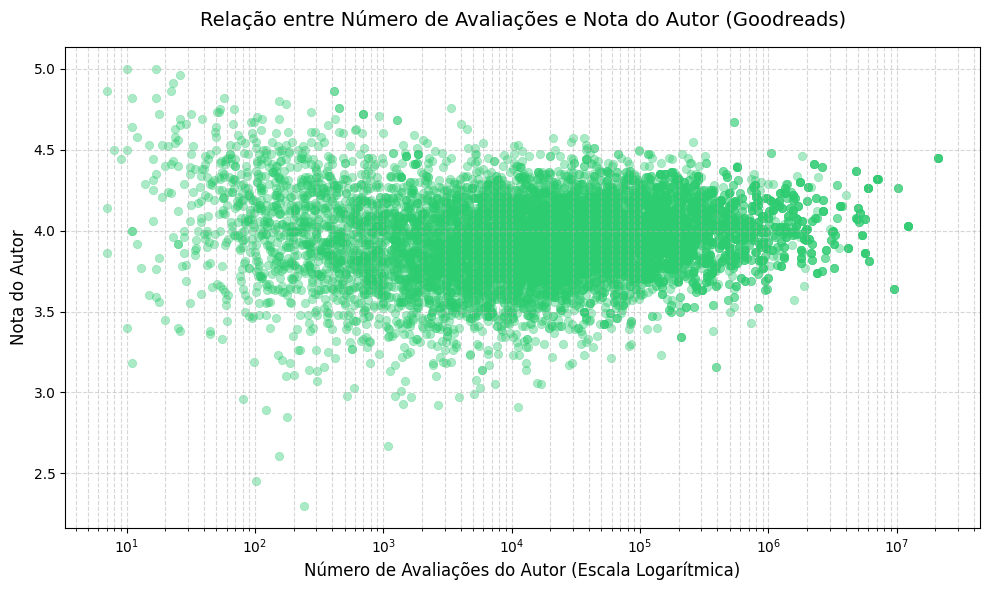

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configura o tamanho da figura
plt.figure(figsize=(10, 6))

# Cria o gráfico de dispersão
sns.scatterplot(
    data=livros,
    x='n_avaliacoes_autor',
    y='nota_autor',
    alpha=0.4,
    color='#2ecc71',
    edgecolor=None
)

# Customização e formatação
plt.title('Relação entre Número de Avaliações e Nota do Autor (Goodreads)', fontsize=14, pad=15)
plt.xlabel('Número de Avaliações do Autor (Escala Logarítmica)', fontsize=12)
plt.ylabel('Nota do Autor', fontsize=12)

# Como o número de avaliações pode variar muito de escala, aplicamos escala logarítmica no eixo X
plt.xscale('log')
plt.grid(True, which="both", linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 6. Limites da quantificação e da automação

A cadeia de evidência mostrou que o resultado depende de decisões
anteriores. Esta seção generaliza a cautela: escala e velocidade podem
ampliar tanto possibilidades analíticas quanto erros e apagamentos.

A quantificação pode:

- tornar padrões comparáveis;
- revelar exceções e lacunas;
- dar escala a uma investigação.

Mas também pode:

- produzir falsa precisão;
- estabilizar categorias contestáveis;
- privilegiar o que sobreviveu e foi digitalizado;
- apagar ambiguidade, silêncio e contexto;
- ampliar vieses por meio da automação.

Automatizar uma regra aumenta sua velocidade e alcance, não sua validade.
Erros sistemáticos podem ser reproduzidos em grande escala.

A função seguinte resume um corpus. Cada chave nomeia uma informação e
cada expressão calcula seu valor. `nunique()` conta valores distintos;
`sorted(...unique())` organiza as categorias. A função descreve o conjunto,
mas não avalia sua qualidade ou representatividade.

In [28]:
def resumo_corpus(tabela, nome):
    return pd.Series({
        "nome": nome,
        "numero_de_documentos": len(tabela),
        "primeiro_ano": int(tabela["ano"].min()),
        "ultimo_ano": int(tabela["ano"].max()),
        "periodicos": tabela["periodico"].nunique(),
        "generos": ", ".join(sorted(tabela["genero"].unique())),
    })

resumo_corpus(corpus_a, "Documentos de 1890 a 1895")

,0
nome,Documentos de 1890 a 1895
numero_de_documentos,6
primeiro_ano,1890
ultimo_ano,1895
periodicos,3
generos,"carta, editorial, notícia"


### Experimento utilizando os dados do meu projeto (Goodreads) ###

In [30]:
livros = ler_bruto()
pd.Series({
    "nome": "Recorte do Goodreads recebido",
    "numero_de_livros": len(livros),
    "numero_de_autores": livros["id_autor"].nunique(),
    "primeiro_ano": int(livros["ano_publicacao"].min()),
    "ultimo_ano": int(livros["ano_publicacao"].max()),
    "livros_antes_de_1900": int((livros["ano_publicacao"] < 1900).sum()),
    "generos_literarios_principais": livros["genero_1"].nunique(),
    "maximo_de_livros_por_autor": int(livros.groupby("id_autor").size().max()),
    "menor_numero_de_avaliacoes": int(livros["n_avaliacoes"].min()),
    "livros_de_autor_nascido_nos_EUA": round(float(livros["pais_nascimento"].eq("United States").mean()), 3),
})

,0
nome,Recorte do Goodreads recebido
numero_de_livros,10454
numero_de_autores,7780
primeiro_ano,-720
ultimo_ano,2019
livros_antes_de_1900,327
generos_literarios_principais,111
maximo_de_livros_por_autor,6
menor_numero_de_avaliacoes,5
livros_de_autor_nascido_nos_EUA,0.622


**Leitura do resumo.** O ano mínimo (−720) corresponde a obras antigas
datadas antes de Cristo (por exemplo, a *Ilíada*), registradas com ano
negativo. O ano mínimo não é erro, mas mostra que o recorte mistura clássicos
com lançamentos recentes. O máximo de seis livros por autor e o mínimo de cinco
avaliações sugerem regras de seleção que não foram documentadas. A proporção
de autores nascidos nos EUA (cerca de 62% no valor bruto; um pouco mais após a
padronização de cidades e estados americanos feita na Unidade 3) indica forte
concentração anglófona.

## U01-A11 — Atividade — ficha do corpus

O resumo computacional descreve propriedades do conjunto, enquanto os
limites exigem argumentação. A ficha reúne ambos em uma delimitação do
corpus adequada à pergunta do estudante.

**Modalidade:** produção individual seguida de revisão em dupla.
**Tempo sugerido:** 30 minutos individuais e 15 minutos em dupla.
**Produto:** ficha preenchida e uma revisão motivada pelo comentário do
colega.

Primeiro, responda aos sete itens com base em seu projeto. Depois, troque a
ficha com um colega. A revisão deve localizar um critério impreciso, uma
ausência pouco discutida e uma conclusão que talvez exceda o corpus.

Delimite um corpus inicial e responda:

1. qual população ou universo de interesse orienta a pergunta?
2. o conjunto disponível é amostra, corpus ou coleção de conveniência?
3. quais são os critérios de inclusão e exclusão?
4. quais formatos e metadados existem?
5. que grupos, vozes ou períodos podem estar ausentes?
6. a que conjunto uma conclusão poderá se referir?
7. quem produziu, classificou, financiou e mantém os dados?

### Minha ficha do corpus

**Universo de interesse:**
Livros catalogados no Goodreads e o reconhecimento que recebem dos usuários
dessa rede social de catalogação e avaliação de livros. O interesse mais amplo
é a desigualdade de gênero no reconhecimento literário em espaços digitais, mas
as conclusões ficarão restritas ao recorte.

**O conjunto é amostra, corpus ou coleção de conveniência? Por quê?**
É uma **coleção de conveniência** tratada como corpus delimitado. Não é amostra
probabilística: não conheço o procedimento que escolheu os 10.454 livros entre
os milhões catalogados na rede. Algumas pistas sugerem um processo de seleção
não aleatório: cada autor aparece no máximo seis vezes, todos os livros têm pelo
menos cinco avaliações e o ano mais recente é 2019. Essas pistas precisam ser
confirmadas com quem produziu o arquivo.

**Unidade de análise:**
O livro (obra catalogada), identificado por `id_livro`. Atributos do autor
(`genero_autor`, `pais_nascimento`, `nota_autor`, `n_avaliacoes_autor`) são
repetidos em cada livro do mesmo autor.

**Critérios de inclusão e exclusão:**
Inclusão: todos os livros do arquivo recebido, sem filtro prévio. Exclusões
apenas em análises de sensibilidade e sempre registradas: livros publicados
antes de 1990 (para reduzir o efeito do tempo de exposição), livros com rótulo
de gênero duvidoso (a ser definido na Unidade 3) e gêneros literários com menos
de 30 livros em algum dos grupos (nas comparações por gênero literário).

**Formatos e metadados necessários:**
CSV estruturado (UTF-8 com BOM, separado por vírgula) com 15 colunas.
Metadados necessários e ainda ausentes: data e método de coleta, critério de
seleção, versão do Goodreads consultada, regra de atribuição do gênero da
autoria e licença ou termos de uso. Esses metadados serão registrados em um
arquivo de proveniência próprio.

**Ausências e silêncios documentais:**
- pessoas autoras não binárias, apagadas pelo campo binário;
- coautorias: só há um autor por livro;
- leitores: não sei quem avalia (gênero, país, idade);
- livros com poucas avaliações ou nenhuma, que parecem ter ficado fora;
- literaturas fora do eixo anglófono: cerca de 62% dos livros são de autores
  registrados como nascidos nos Estados Unidos e cerca de 12% no Reino Unido
  (valores brutos, antes da padronização feita na Unidade 3);
- livros publicados depois de 2019;
- o conteúdo das resenhas, que mostraria o tipo de reconhecimento.

**Alcance possível das conclusões:**
Afirmações do tipo “neste recorte de 10.454 livros do Goodreads, livros
registrados como de autoria feminina tiveram mediana de avaliações X vezes a dos
livros de autoria masculina”. Não é possível generalizar para todo o Goodreads,
para outras redes, para o mercado editorial nem para a recepção crítica.

**Instituições, trabalho e autoridade sobre os dados:**
Os registros foram produzidos por usuários do Goodreads, uma rede pertencente
à Amazon desde 2013 (segundo reportagem do Slashdot de 2020; vale confirmar em
fonte institucional). As categorias de gênero literário vêm das estantes criadas
pelos usuários. A extração, a seleção dos livros, a atribuição do gênero da
autoria e a tradução das colunas foram feitas por terceiros não identificados.
Eu mantenho a cópia local e respondo pelas transformações seguintes. Os autores
listados não participaram da produção do arquivo nem consentiram com esta
análise.

## Referências e leituras

Depois de preencher e revisar a ficha, confronte suas decisões com os
debates sobre números situados, limpeza e construção de bases históricas.

- D'IGNAZIO, Catherine; KLEIN, Lauren F. (2020). *Data Feminism*,
  capítulo “The Numbers Don't Speak for Themselves”.
- RAWSON, Katie; MUÑOZ, Trevor (2019). “Against Cleaning”.
- RODRIGUES, Aldair (2020). “Humanidades digitais e diáspora africana:
  questões éticas e metodológicas na elaboração de uma base de dados
  sobre a população escravizada de Mariana (século XVIII)”.

Dados completos e links: `referencias.md`.

## Síntese

Reúna a delimitação técnica e a crítica das condições de produção. O
produto que segue para a oficina é uma ficha capaz de explicar tanto o que
integra o corpus quanto o que permanece ausente.

O corpus não é um recipiente neutro. Ele materializa decisões de pesquisa
e processos anteriores de produção, preservação e acesso. No próximo
notebook, pergunta, operacionalização e corpus serão reunidos em uma
proposta inicial coerente.